# Interactive Mapper
2026/2/5


In [1]:
import sys
from pathlib import Path

import os

# 導入模組
from ivs_tools.io.h5utils import HDF5Analyzer
from ivs_tools.physics.schottky_analyzer import SchottkyAnalyzer

root_path  ='/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"

h5map_path = os.path.join(root_path, filename)

# 初始化 (自動載入)
h5map = HDF5Analyzer(h5map_path)

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

h5map.print_usage()

DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------
HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
----------------------------------------
  • load_metadata(): 加載元數據
  • load_current_map(): 加載電流映射
  • load_bias_vector(): 加載偏壓序列
  • l

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['font.sans-serif'] = ["Arial"]
rcParams['font.family'] = "sans-serif"

from ipywidgets import IntSlider, Checkbox, FloatSlider, Dropdown, VBox, HBox, Output, Label
from IPython.display import display

def create_slice_viewer(analyzer):
    # --- 0. 關鍵修復：先關閉所有舊圖，避免 Canvas 衝突 ---
    plt.close('all')
    
    # --- 1. 數據準備 ---
    current_3d_raw = analyzer.current_map
    bias_vector = analyzer.bias_vector  # 獲取真正的 Bias 數據
    x_pixels = analyzer.metadata.x_pixels
    y_pixels = analyzer.metadata.y_pixels
    bias_points = len(bias_vector)
    
    # 重塑數據
    current_3d = current_3d_raw.reshape(bias_points, y_pixels, x_pixels)

    # --- 2. 初始化持久化圖表 ---
    plt.ioff() 
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.2]})
    
    plt.ion()
    
    # 初始狀態
    init_idx = bias_points // 2
    current_pos = {'x': x_pixels // 2, 'y': y_pixels // 2}
    
    # 左圖初始化
    im = ax1.imshow(current_3d[init_idx, :, :], cmap='Blues_r', origin='lower', aspect='equal')
    marker, = ax1.plot(current_pos['x'], current_pos['y'], 'ro', markersize=5, markeredgecolor='white')
    cbar = fig.colorbar(im, ax=ax1, shrink = 0.3, aspect = 7, pad = 0.07)
    
    # 右圖初始化 (使用實際的 bias_vector)
    iv_line, = ax2.plot(bias_vector, current_3d[:, current_pos['y'], current_pos['x']], 'b-o', markersize=3)
    bias_dot, = ax2.plot(bias_vector[init_idx], 0, 'ro') # 當前位置紅點
    
    # --- 3. 更新函數 ---
    def update_display(change=None):
        b_idx = bias_slider.value
        current_v = bias_vector[b_idx]
        is_log = log_checkbox.value
        
        # 更新數值標籤
        bias_val_label.value = f"Current Bias: {current_v:.3f} V"
        
        # 更新左圖
        plot_data = np.log10(np.abs(current_3d[b_idx, :, :]) + 1e-20) if is_log else current_3d[b_idx, :, :]
        im.set_data(plot_data)
        if auto_range_checkbox.value:
            im.set_clim(np.nanmin(plot_data), np.nanmax(plot_data))
        else:
            im.set_clim(range_min_slider.value, range_max_slider.value)
        
        marker.set_data([current_pos['x']], [current_pos['y']])
        ax1.set_title(f'Map at {current_v:.3f} V (Index: {b_idx})')
        
        # 更新右圖
        iv_data = current_3d[:, current_pos['y'], current_pos['x']]
        iv_line.set_ydata(iv_data)
        bias_dot.set_data([current_v], [iv_data[b_idx]]) # 更新紅點到正確的電壓位置
        
        if is_log:
            ax2.set_yscale('log')
        else:
            ax2.set_yscale('linear')
        ax2.set_xlabel('Voltage (V)', fontsize = 15)
        ax2.set_ylabel('Current (A)', fontsize = 15)
        ax2.tick_params(labelsize = 12)
        ax2.set_title(f'IV at Pixel ({current_pos["x"]}, {current_pos["y"]})')
        ax2.relim()
        ax2.autoscale_view()
        
        fig.canvas.draw_idle()

    # --- 4. 事件處理 ---
    def onclick(event):
        if event.inaxes == ax1:
            ix, iy = int(round(event.xdata)), int(round(event.ydata))
            if 0 <= ix < x_pixels and 0 <= iy < y_pixels:
                current_pos['x'], current_pos['y'] = ix, iy
                update_display()

    fig.canvas.mpl_connect('button_press_event', onclick)

    # --- 5. UI 組件設定 ---
    # (1) Slider 
    bias_slider = IntSlider(
        min=0, max=bias_points-1, value=init_idx, 
        description='Bias Index:', 
        layout={'width': '50%'} 
    )
    
    # (2) 顯示真實電壓的 Label
    bias_val_label = Label(value=f"Current Bias: {bias_vector[init_idx]:.3f} V")
    
    log_checkbox = Checkbox(value=False, description='Log Scale')
    cmap_dropdown = Dropdown(options=['Blues_r', 'viridis', 'jet'], value='Blues_r', description='Cmap:')
    auto_range_checkbox = Checkbox(value=True, description='Auto Range')
    
    # 這裡的範圍滑桿也改用真正的數據範圍
    data_min, data_max = np.nanmin(current_3d), np.nanmax(current_3d)
    range_min_slider = FloatSlider(min=data_min, max=data_max, value=data_min, description='Min:', layout={'width': '25%'})
    range_max_slider = FloatSlider(min=data_min, max=data_max, value=data_max, description='Max:', layout={'width': '25%'})

    # 綁定
    for w in [bias_slider, log_checkbox, cmap_dropdown, auto_range_checkbox, range_min_slider, range_max_slider]:
        w.observe(update_display, names='value')

    # --- 6. 佈局顯示 ---
    ui = VBox([
        HBox([bias_slider, bias_val_label]), # Slider 與 Label 橫向排列
        HBox([log_checkbox, cmap_dropdown, auto_range_checkbox]),
        HBox([range_min_slider, range_max_slider])
    ])
    
    display(ui)
    display(fig.canvas)
    update_display()


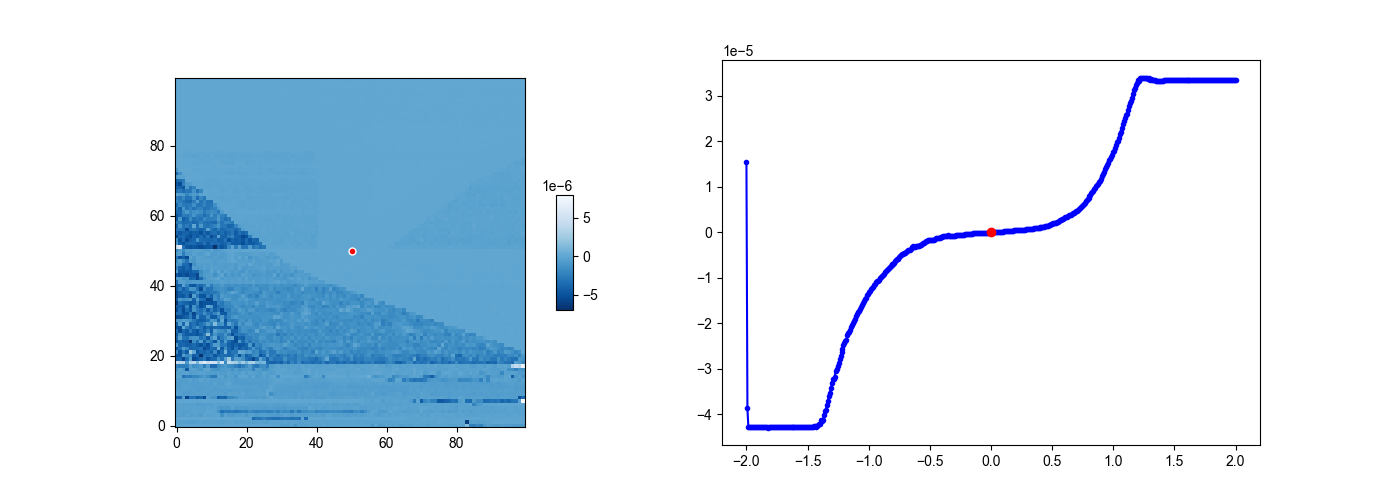

In [3]:
%matplotlib ipympl
create_slice_viewer(h5map)

In [6]:
%matplotlib ipympl
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, Checkbox, Dropdown, VBox, HBox, Output, IntText, Label
from IPython.display import display, clear_output

def create_slice_viewer(analyzer):
    # --- 1. 數據初始化與自動形狀檢查 ---
    current_3d_raw = analyzer.current_map
    bias_points = current_3d_raw.shape[0]
    nx = analyzer.metadata.x_pixels
    ny = analyzer.metadata.y_pixels
    
    # 強制檢查數據長度
    if current_3d_raw.shape[1] != nx * ny:
        print(f"Warning: Metadata defines {nx}x{ny}={nx*ny} pixels, but data has {current_3d_raw.shape[1]}")
        # 修正 nx, ny (假設是正方形)
        nx = ny = int(np.sqrt(current_3d_raw.shape[1]))
        print(f"Auto-adjusted to {nx}x{ny}")

    # 重塑數據為 (Bias, Y, X)
    current_3d = current_3d_raw.reshape(bias_points, ny, nx)
    
    # 建立輸出元件
    output = Output()
    
    # 紀錄當前點擊座標
    current_pos = {'x': nx // 2, 'y': ny // 2}

    # --- 2. 核心繪圖函數 ---
    def render(change=None):
        with output:
            # 讀取當前 UI 數值
            b_idx = bias_slider.value
            is_log = log_checkbox.value
            cmap = cmap_dropdown.value
            cx, cy = x_input.value, y_input.value
            
            # 限制邊界
            cx = max(0, min(nx-1, cx))
            cy = max(0, min(ny-1, cy))
            
            clear_output(wait=True)
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
            
            # 左圖：Map
            img_data = current_3d[b_idx, :, :]
            if is_log:
                img_data = np.log10(np.abs(img_data) + 1e-15) # 避免 log(0)
            
            im = ax1.imshow(img_data, cmap=cmap, origin='lower')
            ax1.plot(cx, cy, 'rx', markersize=10, markeredgewidth=2) # 標記中心
            ax1.set_title(f"Bias Index: {b_idx} | Pixel: ({cx}, {cy})")
            plt.colorbar(im, ax=ax1)
            
            # 右圖：IV Curve
            iv_curve = current_3d[:, cy, cx]
            ax2.plot(iv_curve, 'b-o', markersize=3)
            ax2.axvline(x=b_idx, color='r', linestyle='--', alpha=0.5)
            ax2.set_title(f"IV Characteristics at ({cx}, {cy})")
            ax2.set_xlabel("Bias Index")
            ax2.set_ylabel("Current (A)")
            if is_log: ax2.set_yscale('log')
            ax2.grid(True)
            
            plt.tight_layout()
            plt.show()

    # --- 3. UI 組件 ---
    bias_slider = IntSlider(min=0, max=bias_points-1, value=0, description='Bias:', layout={'width': '95%'})
    x_input = IntText(value=nx//2, description='X:', layout={'width': '150px'})
    y_input = IntText(value=ny//2, description='Y:', layout={'width': '150px'})
    log_checkbox = Checkbox(value=False, description='Log Scale')
    cmap_dropdown = Dropdown(options=['hot', 'viridis', 'jet', 'gray'], value='hot', description='Cmap:')

    # 綁定事件
    for widget in [bias_slider, x_input, y_input, log_checkbox, cmap_dropdown]:
        widget.observe(render, names='value')

    # 佈局
    ui = VBox([
        bias_slider,
        HBox([Label("Target Pixel:"), x_input, y_input]),
        HBox([log_checkbox, cmap_dropdown])
    ])
    
    display(ui, output)
    render()

create_slice_viewer(h5map)

Output()